# Monte Carlo Simulation Analysis

This notebook uses the reusable tools in `src/` to visualise GBM simulations and compare them against closed-form results.
Everything here is **model-only** (no market data yet). The computations live in `src/analytics.py` and `src/valuation.py`,
and the figures in `src/plotting.py`, so the Streamlit app can reuse the same code.

1. **Spaghetti plot**: 1,000 GBM paths and how dispersion grows over time
2. **Terminal histogram**: 10,000 terminal prices against the theoretical lognormal density
3. **Option valuation engine**: Monte Carlo vs Black–Scholes, confidence intervals, convergence, and put–call parity

In [40]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Make the repository-level src package importable whether the kernel starts
# in the project root or in the notebooks directory.
project_root = Path.cwd().resolve()
if not (project_root / "src").is_dir():
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.valuation import (
    convergence_study,
    parity_sampling_noise,
    price_chain,
    price_with_confidence,
    put_call_parity_table,
    simulate_terminal_prices,
)

from src.gbm import simulate_gbm_paths
from src.analytics import terminal_summary

from src.plotting import (
    plot_convergence,
    plot_dispersion,
    plot_log_qq,
    plot_spaghetti,
    plot_strike_comparison,
    plot_terminal_histogram,
)

plt.rcParams.update({"figure.figsize": (11, 5), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 0. Parameters

One place to change the market assumptions. Later these will come from live data:
$S_0$ from the spot price, $\sigma$ from historical or implied volatility, and $r$ from a treasury yield.

In [41]:
S0 = 100.0        # spot price
r = 0.05          # annual risk-free rate
sigma = 0.1     # annual volatility
T = 1.0           # horizon in years
N_STEPS = 252     # one step per trading day
SEED = 42

N_PATHS_SPAGHETTI = 1_000
N_TERMINAL = 10_000

time_grid = np.linspace(0.0, T, N_STEPS + 1)

## 1. Spaghetti Plot: 1,000 GBM Paths

Under the risk-neutral measure each path follows

$$dS_t = r S_t\,dt + \sigma S_t\,dW_t \quad\Longrightarrow\quad S_t = S_0\, e^{(r-\frac12\sigma^2)t + \sigma W_t}.$$

Picture a fan opening up. Every path starts at $S_0$, and the spread grows with $\sqrt{t}$.
The shaded bands are the simulated 5–95% and 25–75% ranges. The dashed line is the theoretical mean $S_0 e^{rt}$.

paths shape: (1000, 253)


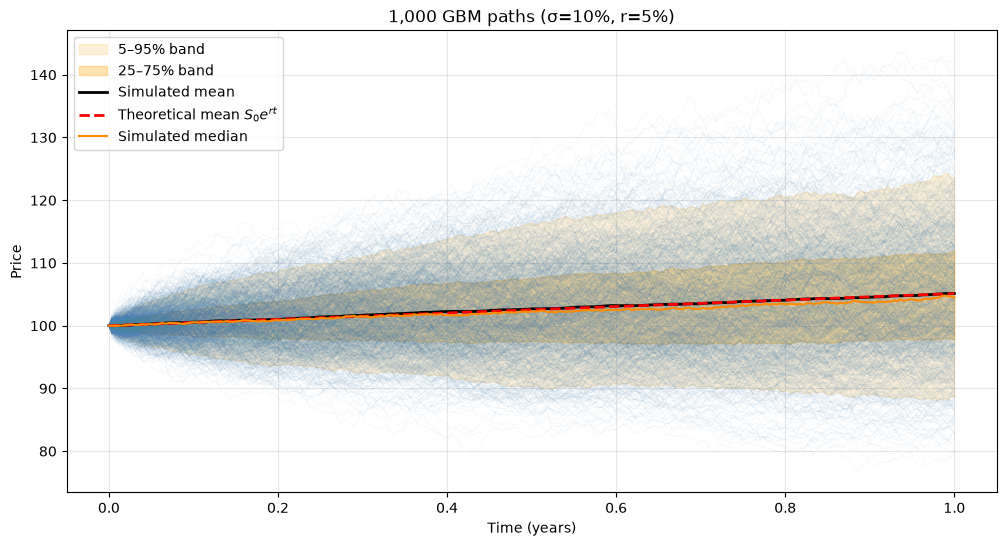

In [42]:
paths = simulate_gbm_paths(S0, r, sigma, T, N_STEPS, N_PATHS_SPAGHETTI, rng=np.random.default_rng(SEED))
print("paths shape:", paths.shape)  # (n_paths, n_steps + 1)

fig = plot_spaghetti(paths, time_grid, S0, r, sigma)

### Volatility expansion

Two ways to see the fan widening, each compared with its closed form:

- **Log-price dispersion:** $\operatorname{sd}(\ln S_t) = \sigma\sqrt{t}$. This is the "pure" volatility and grows like a square root.
- **Price dispersion:** $\operatorname{sd}(S_t) = S_0 e^{rt}\sqrt{e^{\sigma^2 t}-1}$. This grows faster than a square root because of the lognormal skew.

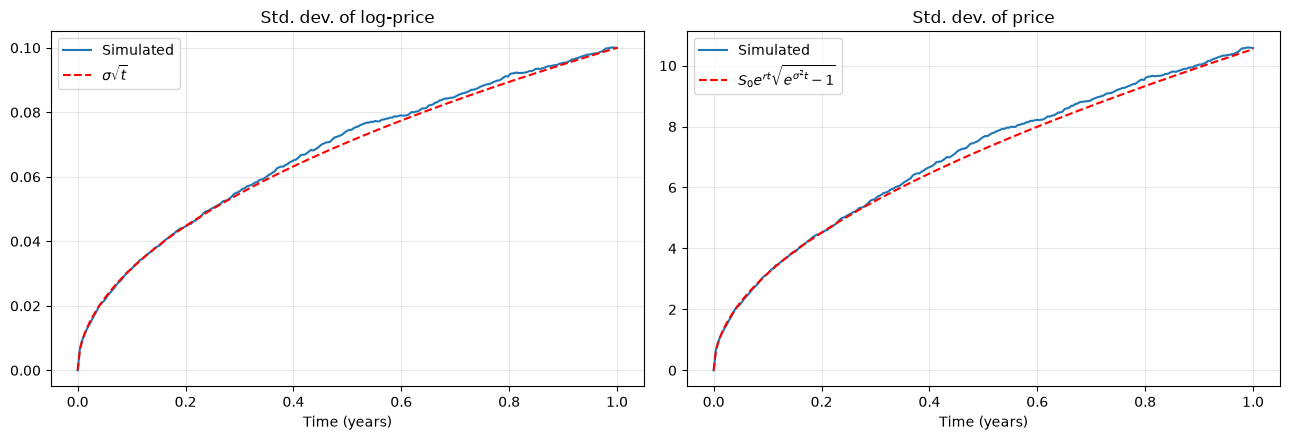

In [43]:
fig = plot_dispersion(paths, time_grid, S0, r, sigma)

## 2. Terminal Histogram: 10,000 Runs

Because $\ln S_T \sim \mathcal N\!\big(\ln S_0 + (r-\tfrac12\sigma^2)T,\ \sigma^2T\big)$, the terminal price is **lognormal**.
`simulate_terminal_prices` samples $S_T$ in one step without building paths, which is much cheaper.

Three "centres" separate in a skewed distribution:
**mode < median < mean**. The peak (most likely single value) sits *below* the mean,
while a long right tail pulls the mean up. The red shaded areas are the extreme 1% tails on each side.

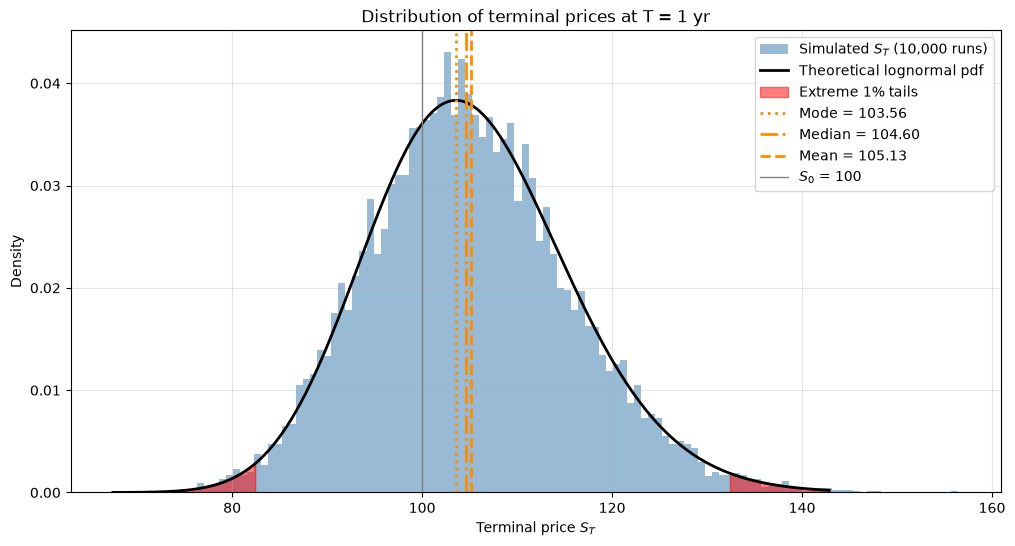

In [44]:
ST = simulate_terminal_prices(S0, r, sigma, T, N_TERMINAL, rng=np.random.default_rng(SEED))

fig = plot_terminal_histogram(ST, S0, r, sigma, T)

In [45]:
terminal_summary(ST, S0, r, sigma, T, drop_levels=(0.7, 0.5), gain_levels=(1.5,))

,Simulated,Theoretical,Difference
Mean,105.0260,105.1271,-0.1011
Median,104.4651,104.6028,-0.1376
Std. dev.,10.5958,10.5390,0.0567
Skewness,0.3081,0.3018,0.0063
1% quantile,82.4992,82.8917,-0.3925
99% quantile,132.3903,132.0004,0.3899
P(S_T < 0.7·S0),0.0001,0.0000,0.0001
P(S_T < 0.5·S0),0.0000,0.0000,-0.0000
P(S_T > 1.5·S0),0.0001,0.0002,-0.0001


**Q–Q check.** If the simulation is right, $\ln S_T$ should be exactly normal, so the points should sit on the straight line.

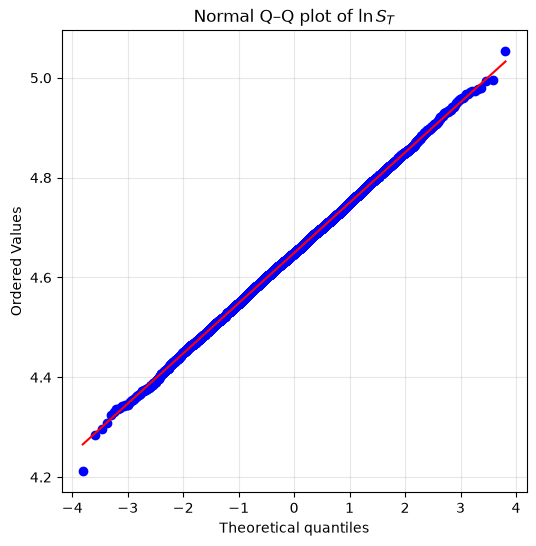

In [46]:
fig = plot_log_qq(ST)

## 3. Option Valuation Engine

### 3.1 One option: price with a confidence interval

A Monte Carlo price is a *sample average* of discounted payoffs, so it comes with a standard error:

$$\hat V = e^{-rT}\frac1N\sum_i \text{payoff}(S_T^{(i)}),\qquad \text{SE} = e^{-rT}\frac{\operatorname{sd}(\text{payoff})}{\sqrt N}.$$

`price_with_confidence` (in `src/valuation.py`) wraps `compare_call_prices` / `compare_put_prices` and adds the SE and a 95% CI,
so we can tell whether a gap is real or just noise.

In [47]:
pd.DataFrame([
    price_with_confidence(ST, S0, 100, T, r, sigma, "call"),
    price_with_confidence(ST, S0, 100, T, r, sigma, "put"),
]).set_index("kind")

,strike,mc_price,bs_price,std_error,ci_low,ci_high,abs_diff,z_score,bs_in_ci
kind,,,,,,,,,
call,100.0000,6.7516,6.8050,0.0774,6.5999,6.9033,0.0534,-0.6898,True
put,100.0000,1.9707,1.9279,0.0388,1.8946,2.0468,0.0428,1.1024,True


### 3.2 Across the strike range

Here we price calls and puts from deep in-the-money to deep out-of-the-money using the **same** 10,000 terminal prices.
The error bars are the 95% CIs. The right-hand panel shows the error measured in standard errors:
most points should land inside ±1.96.

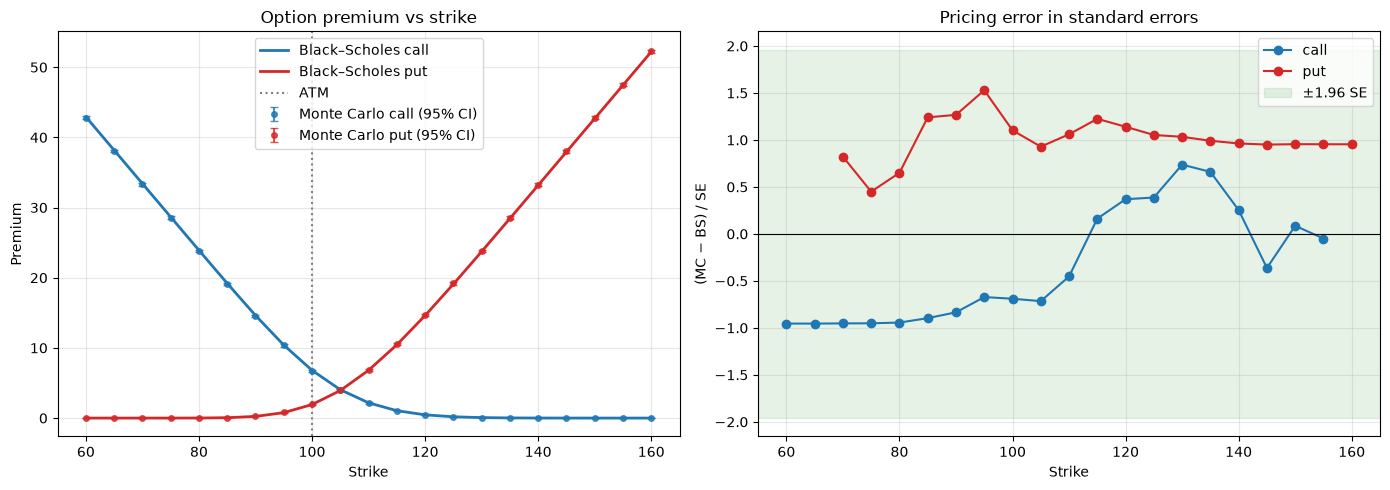

BS price inside the MC 95% CI for 93% of 42 options


mc_price         bs_price         std_error       
kind         call     put     call     put      call    put
strike                                                     
60.0000   42.8301  0.0000  42.9262  0.0000    0.1008 0.0000
65.0000   38.0739  0.0000  38.1701  0.0000    0.1008 0.0000
70.0000   33.3180  0.0002  33.4140  0.0000    0.1008 0.0002
75.0000   28.5628  0.0011  28.6586  0.0008    0.1008 0.0008
80.0000   23.8151  0.0097  23.9100  0.0083    0.1005 0.0020
85.0000   19.1105  0.0612  19.1997  0.0542    0.0995 0.0057
90.0000   14.5486  0.2554  14.6288  0.2395    0.0962 0.0125
95.0000   10.3455  0.8084  10.4053  0.7721    0.0890 0.0238
100.0000   6.7516  1.9707   6.8050  1.9279    0.0774 0.0388
105.0000   4.0014  3.9766   4.0461  3.9252    0.0625 0.0554
110.0000   2.1528  6.8842   2.1739  6.8092    0.0467 0.0708
115.0000   1.0595 10.5471   1.0542 10.4456    0.0325 0.0829
120.0000   0.4704 14.7141   0.4625 14.6100    0.0213 0.0912
125.0000   0.1896 19.1895   0.1845 19.0881    0.0133 0.0962
130.0000   0.0731 23.8291   0.0673 23.7271    0.0079 0.0987
135.0000   0.0255 28.5377   0.0226 28.4386    0.0044 0.1000
140.0000   0.0076 33.2759   0.0070 33.1792    0.0023 0.1005
145.0000   0.0016 38.0261   0.0021 37.9303    0.0011 0.1007
150.0000   0.0006 42.7812   0.0006 42.6850    0.0006 0.1008
155.0000   0.0001 47.5369   0.0001 47.4407    0.0001 0.1008
160.0000   0.0000 52.2929   0.0000 52.1967    0.0000 0.1008

In [48]:
strikes = np.arange(60, 165, 5)
chain = price_chain(ST, S0, strikes, T, r, sigma)

fig = plot_strike_comparison(chain, S0)
plt.show()

print(f"BS price inside the MC 95% CI for {chain.bs_in_ci.mean():.0%} of {len(chain)} options")
chain.pivot(index="strike", columns="kind", values=["mc_price", "bs_price", "std_error"]).round(4)

A note on the right-hand panel: calls and puts at the same strike use the same random draws, so their errors are **correlated**.
Read it as one sample of noise, not 42 independent ones.

### 3.3 Convergence: how many simulations is "enough"?

Monte Carlo error shrinks like $1/\sqrt N$: you need **4× the runs to halve the error**.
We reprice the ATM call over 20 independent seeds at each $N$, up to 10,000 runs.

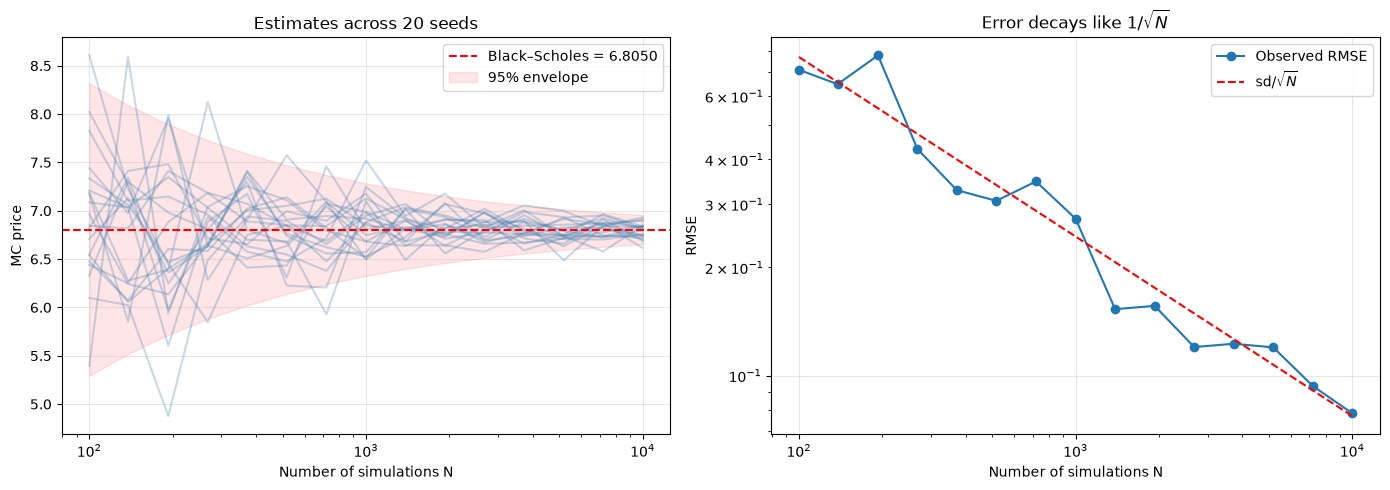

In [49]:
K_ATM = 100.0
n_grid = np.unique(np.logspace(2, 4, 15).astype(int))   # 100 ... 10,000

# Errors over 20 independent seeds per N. The theoretical RMSE is sd(discounted payoff) / sqrt(N),
# with the payoff sd estimated from a large reference sample.
study = convergence_study(S0, K_ATM, T, r, sigma, n_grid, n_seeds=20, kind="call", seed=SEED)

fig = plot_convergence(study)

### 3.4 Sanity check: put–call parity

For European options, $C - P = S_0 - Ke^{-rT}$ holds *exactly*, whatever the model.
On a simulated sample the gap equals the sampling error in $\bar S_T$. That gives a cheap way to test the simulator.

In [50]:
parity = put_call_parity_table(ST, S0, strikes, T, r, sigma)
print("Discounted mean of S_T minus S0 (pure sampling noise):", parity_sampling_noise(ST, S0, T, r))
parity.head(8)

Discounted mean of S_T minus S0 (pure sampling noise): -0.0961815966005446


,MC C - P,BS C - P,S0 - K e^{-rT}
strike,,,
60.0000,42.8301,42.9262,42.9262
65.0000,38.0739,38.1701,38.1701
70.0000,33.3178,33.4139,33.4139
75.0000,28.5616,28.6578,28.6578
80.0000,23.8055,23.9016,23.9016
85.0000,19.0493,19.1455,19.1455
90.0000,14.2932,14.3894,14.3894
95.0000,9.5370,9.6332,9.6332
